# 03 · A physics-based (grey-box) CO₂ model: ODEs, stiffness and shooting
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/03_ode_physics_model.ipynb)

A well-mixed room obeys the CO₂ mass balance

$$V\frac{dC}{dt} = G\,N(t) - Q\,(C - C_{out}) \quad\Rightarrow\quad \frac{dC}{dt} = g\,N(t) - \lambda\,(C - C_{out}) + s$$

with effective generation *g* = G/V [ppm per person-hour], air-change rate λ = Q/V [1/h], background *C*<sub>out</sub> [ppm] and an optional constant source *s* [ppm/h] for model error. Here *N(t)* is the building occupancy proxy (notebook 00), so *g* is an effective rather than a physical emission rate.

| Unit topic | Where |
|---|---|
| 2.1 Optimisation | linear least squares (equation error) and nonlinear least squares (output error) |
| 2.3 Linear systems | over-determined system solved by QR/SVD (`lstsq`) |
| 7.1 Finite differences | derivative estimates and their O(h), O(h²) error |
| 7.2–7.5 ODEs / IVPs, Euler, Runge–Kutta | own integrators, verified convergence orders |
| 9.1–9.3 Stability, stiff ODEs, implicit methods | stability functions, sensor-lag stiff system, implicit Euler/trapezoid, SciPy BDF |
| 9.4 BVPs and the shooting method | two-point gap fill with secant root finding |
| Sensitivity analysis (brief) | ±20 % parameter perturbations |

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from sensorfill import benchmark as bm, interpolation as itp, ode, study, plotting
from sensorfill.plotting import plt
plotting.setup()
s = study.load_study(PROCESSED, "co2")
h = study.DT_HOURS

## 1. Verification: finite differences and integrator orders

In [3]:
hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
fd = {sch: [] for sch in ("forward", "backward", "central")}
for hh in hs:
    x = np.arange(0, 3, hh)
    for sch in fd:
        d = ode.finite_difference(np.sin(x), hh, sch)
        fd[sch].append(np.max(np.abs(d[2:-2] - np.cos(x[2:-2]))))
fd = pd.DataFrame(fd, index=pd.Index(hs, name="h"))
print("observed order (log2 of successive error ratios):")
print(np.log2(fd.iloc[:-1].to_numpy() / fd.iloc[1:].to_numpy()).mean(axis=0).round(2), fd.columns.tolist())

# Integrator orders on the CO2 model. The reference is the exact solution for the SAME
# piecewise-linear occupancy input, so only time-integration error is measured.
p_true = ode.CO2Params(g=5.0, lam=1.5, c_out=420.0)
rows = {}
for m in ode.ORDER:
    errs = []
    for n in (24, 48, 96, 192):
        t = np.linspace(0, 12, n + 1)
        o = 10 + 5 * np.sin(2 * np.pi * t / 6)
        exact = ode.simulate_co2(p_true, t, o, 420, "exact_linear")
        errs.append(np.max(np.abs(ode.simulate_co2(p_true, t, o, 420, m) - exact)))
    rows[m] = {"theory": ode.ORDER[m], "observed": np.log2(errs[-2] / errs[-1]), "max error at h=1/16 h [ppm]": errs[-1]}
pd.DataFrame(rows).T

observed order (log2 of successive error ratios):
[1.   1.   1.97] ['forward', 'backward', 'central']


,theory,observed,max error at h=1/16 h [ppm]
euler,1.0,1.050777,0.425141
implicit_euler,1.0,0.955933,0.397902
heun,2.0,2.103997,0.013783
midpoint,2.0,2.103997,0.013783
trapezoid,2.0,2.001982,0.006422
rk4,4.0,4.111257,0.000006


The observed orders match theory (1, 2 and 4) for all six integrators. The reference is the closed-form solution of the linear ODE for the same piecewise-linear input. (An earlier version compared against a smooth input on a fine grid; RK4 then appeared to be only second order, because the O(h²) error of linearly interpolating the *input* dominated. That is a useful reminder that a method's order can be masked by data resolution.) RK4 at the data's 10-minute step is accurate to about 10⁻⁴–10⁻³ ppm. That is negligible against 8 ppm of sensor noise, so **time-integration error is not a limiting factor** in this project; model-form and parameter error are.

## 2. Stability and stiffness
For $y' = -\lambda y$, one step multiplies the error by $R(z)$ with $z = -h\lambda$. A step is stable when |R(z)| ≤ 1.

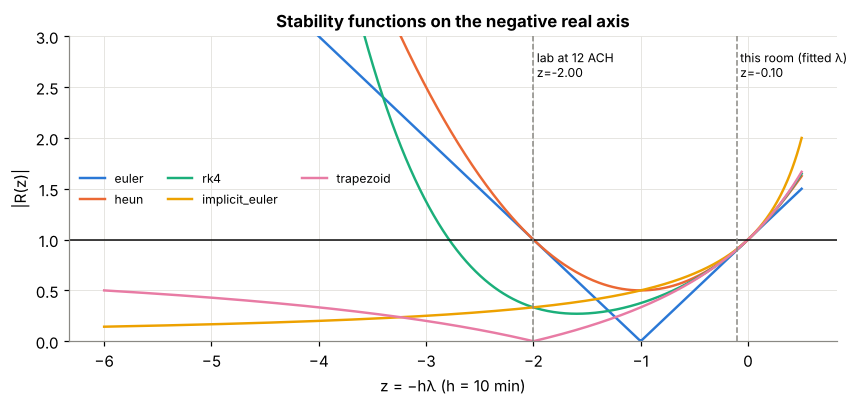

In [4]:
z = np.linspace(-6, 0.5, 600)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, m in enumerate(("euler", "heun", "rk4", "implicit_euler", "trapezoid")):
    ax.plot(z, np.abs([ode.amplification_factor(m, zz) for zz in z]), color=plotting.PALETTE[i], label=m)
ax.axhline(1, color=plotting.INK, lw=1)
for lam, lab in ((0.63, "this room (fitted λ)"), (12, "lab at 12 ACH")):
    ax.axvline(-h * lam, color=plotting.MUTED, ls="--", lw=1); ax.text(-h * lam, 2.6, f" {lab}\n z={-h*lam:.2f}", fontsize=8)
ax.set_ylim(0, 3); ax.set_xlabel("z = −hλ (h = 10 min)"); ax.set_ylabel("|R(z)|"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Stability functions on the negative real axis")
_ = plotting.save(fig, "03_stability_functions")

The room itself is far from stiff (z ≈ −0.1). Stiffness appears when a **fast process is coupled to a slow one**. Here the CO₂ *sensor* has its own diffusion lag of about 1 minute, while the room's time constant is about 1.5 hours:

$$\dot C = g N - \lambda (C - C_{out}), \qquad \dot S = (C - S)/\tau_s,\quad \tau_s = 1/60\ \mathrm{h}.$$

The stiffness ratio is (1/τ<sub>s</sub>)/λ ≈ 100. An explicit method must use h < 2τ<sub>s</sub> (2 minutes) for stability, even though the solution only varies on the scale of hours.

In [5]:
lam, tau = 0.63, 1 / 60
def rhs(t, y):
    N = 15.0 if 9 <= t % 24 < 17 else 0.0
    C, S = y
    return np.array([4.5 * N - lam * (C - 420), (C - S) / tau])
t = np.arange(0, 24 + 1e-9, h)                     # the data's 10-min step: h/tau = 10
J = np.array([[-lam, 0], [1 / tau, -1 / tau]])
print("eigenvalues of the Jacobian [1/h]:", np.linalg.eigvals(J).round(2), "-> stiffness ratio", round((1 / tau) / lam))
fine = solve_ivp(rhs, (0, 24), [420, 420], method="Radau", t_eval=t, rtol=1e-9, atol=1e-9, max_step=0.05)
# max_step stops the adaptive solvers stepping straight over the 09:00 occupancy switch-on
# (with no limit, BDF grows its step during the quiet night and misses the discontinuity).
rows, sols = [], {}
for m in ("euler", "rk4", "implicit_euler", "trapezoid"):
    Y = ode.integrate(rhs, [420, 420], t, m)
    sols[m] = Y[:, 1]
    rows.append({"method": m, "h/tau": h / tau, "max |S - reference| [ppm]": np.nanmax(np.abs(Y[:, 1] - fine.y[1])) if np.isfinite(Y).all() else np.inf})
for m in ("RK45", "BDF"):
    r = solve_ivp(rhs, (0, 24), [420, 420], method=m, t_eval=t, rtol=1e-6, atol=1e-6, max_step=0.25)
    rows.append({"method": f"scipy {m} (adaptive)", "h/tau": np.nan, "max |S - reference| [ppm]": np.max(np.abs(r.y[1] - fine.y[1])), "RHS evaluations": r.nfev})
pd.DataFrame(rows)

eigenvalues of the Jacobian [1/h]: [-60.  +0.j  -0.63+0.j] -> stiffness ratio 95


,method,h/tau,max |S - reference| [ppm],RHS evaluations
0,euler,10.0,8.660891e+85,NaN
1,rk4,10.0,4.265937e+221,NaN
2,implicit_euler,10.0,9.366923e+00,NaN
3,trapezoid,10.0,4.745341e+00,NaN
4,scipy RK45 (adaptive),NaN,5.141292e-02,2306.0
5,scipy BDF (adaptive),NaN,2.563943e-03,467.0


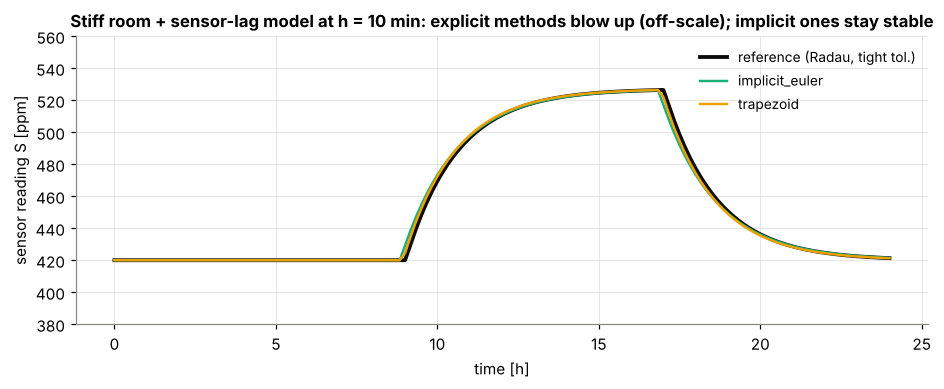

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t, fine.y[1], color=plotting.INK, lw=2.5, label="reference (Radau, tight tol.)")
for i, m in enumerate(("implicit_euler", "trapezoid")):
    ax.plot(t, sols[m], color=plotting.PALETTE[i + 2], label=m)
ax.set_ylim(380, 560); ax.set_xlabel("time [h]"); ax.set_ylabel("sensor reading S [ppm]"); ax.legend()
ax.set_title("Stiff room + sensor-lag model at h = 10 min: explicit methods blow up (off-scale); implicit ones stay stable")
_ = plotting.save(fig, "03_stiff_sensor_lag")

* Explicit Euler and RK4 diverge at h = 10τ<sub>s</sub> (the error is multiplied by |1 − 10| = 9 every step for Euler).
* Implicit Euler is L-stable: it damps the fast mode completely and tracks the slow dynamics.
* The trapezoid rule is A-stable but **not** L-stable. Since R(−∞) = −1, the fast mode is not damped and appears as a small oscillation after each step change in occupancy.
* The remaining error of implicit Euler and the trapezoid rule (a few ppm) is ordinary truncation error at h = 10 min around the occupancy switch-on and switch-off. It is stable error, not growth.
* SciPy's adaptive RK45 stays accurate only by shrinking its step to the fast scale, so it needs many more RHS evaluations than BDF for similar accuracy. That is the practical signature of stiffness.

**Decision.** The fitted room model alone is non-stiff, so RK4 is used, at a cost of 4 RHS evaluations per step. If a sensor-lag state were added, an implicit or BDF integrator would be required.

## 3. Estimating the parameters from training data

In [7]:
y_tr, ts_tr, occ_tr = s.part("train")
y_fill = itp.fill_linear(y_tr)       # only 1-2-step dropouts in training; harmless for fitting
occ_fill = itp.fill_locf(occ_tr)
p_eq = ode.fit_equation_error(y_fill, occ_fill, h)
segments = [(np.arange(144) * h, y_fill[i:i + 144], occ_fill[i:i + 144]) for i in range(0, len(y_fill) - 144, 144)]
p_out, res = ode.fit_output_error(segments, p_eq)
p_out_s, _ = ode.fit_output_error(segments, p_eq, fit_s=True)
tab = pd.DataFrame({"equation error (FD + lstsq)": vars(p_eq), "output error (simulation LSQ)": vars(p_out),
                    "output error + source s": vars(p_out_s)}).T
tab["time constant 1/λ [h]"] = 1 / tab["lam"]
tab.round(3)

,g,lam,c_out,s,time constant 1/λ [h]
equation error (FD + lstsq),0.909,0.053,419.938,0.000,19.048
output error (simulation LSQ),4.472,0.629,449.995,0.000,1.590
output error + source s,4.473,0.629,424.077,16.306,1.589


**Two estimators, very different answers, and why.** The *equation-error* fit regresses a finite-difference derivative on *C* and *N*. Both sides contain the 8 ppm sensor noise, and the central difference amplifies it by 1/(√2·h). This is an **errors-in-variables** problem, and it biases λ towards zero (an "attenuation" bias): a 19-hour time constant is physically implausible for an occupied room. The *output-error* fit simulates each training day and compares levels, not slopes, so noise enters only once and averages out. It gives λ ≈ 0.6 h⁻¹, a time constant of about 1.6 h, which is typical for a mechanically ventilated space. The output-error parameters are used from here on.

**Physical plausibility check.** With *C*<sub>out</sub> ≈ 420–450 ppm (close to the measured night-time minimum and to outdoor background), the steady state for the mean working-day occupancy is $C_{ss} = C_{out} + gN/λ$:

In [8]:
N_work = np.nanmean(occ_tr[(ts_tr.hour >= 10) & (ts_tr.hour < 16) & (ts_tr.dayofweek < 5)])
print(f"mean working-hours occupancy proxy: {N_work:.1f} persons -> predicted C_ss = {p_out.c_out + p_out.g * N_work / p_out.lam:.0f} ppm")
print(f"observed mean working-hours CO2 (train): {np.nanmean(y_tr[(ts_tr.hour >= 10) & (ts_tr.hour < 16) & (ts_tr.dayofweek < 5)]):.0f} ppm")

mean working-hours occupancy proxy: 7.6 persons -> predicted C_ss = 504 ppm
observed mean working-hours CO2 (train): 510 ppm


### Validation of the model itself: free simulation of whole validation days

per-day R² of a 24-h free simulation on validation days: [ 0.55  0.04 -0.02 -0.86 -3.49  0.5   0.43 -0.3  -1.14 -1.6  -0.53 -0.23
  0.03  0.52 -0.52  0.5   0.42 -0.82  0.37  0.69]


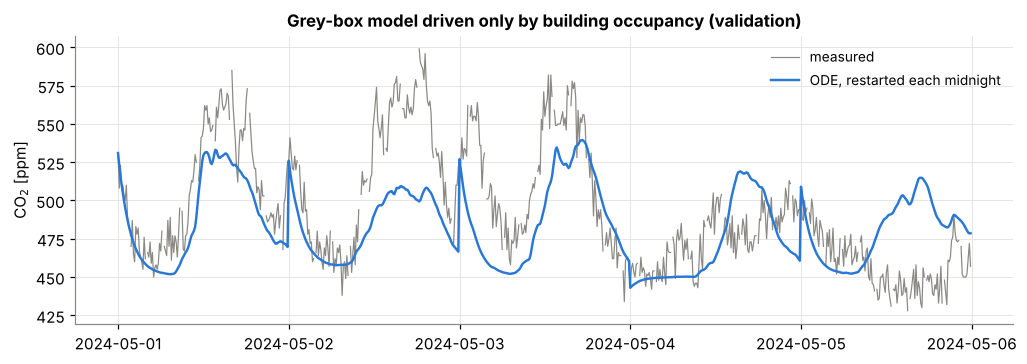

In [9]:
yv, tv, ov = s.part("val")
yvf, ovf = itp.fill_linear(yv), itp.fill_locf(ov)
r2s, sims = [], []
for i in range(0, len(yv) - 144, 144):
    sim = ode.simulate_co2(p_out, np.arange(144) * h, ovf[i:i + 144], yvf[i], "rk4")
    sims.append(sim); r2s.append(1 - np.sum((sim - yvf[i:i + 144]) ** 2) / np.sum((yvf[i:i + 144] - yvf[i:i + 144].mean()) ** 2))
print("per-day R² of a 24-h free simulation on validation days:", np.round(r2s, 2))
fig, ax = plt.subplots(figsize=(11, 3.4))
k = 5 * 144
ax.plot(tv[:k], yv[:k], color=plotting.MUTED, lw=0.8, label="measured")
ax.plot(tv[:k], np.concatenate(sims[:5]), color=plotting.PALETTE[0], label="ODE, restarted each midnight")
ax.set_ylabel("CO$_2$ [ppm]"); ax.legend(); ax.set_title("Grey-box model driven only by building occupancy (validation)")
_ = plotting.save(fig, "03_free_simulation")

The model captures the *timing* of the working-day rise and evening decay. Daily R² varies widely (it is negative on some days). The amplitude is often wrong because the proxy is building-wide occupancy, not this room's. This is the main limitation of the physics route, and it is quantified rather than hidden.

## 4. Gap filling: initial-value vs boundary-value (shooting) formulation
* **IVP:** start at the last reading before the gap and integrate forward. This uses only the left boundary, so it is suitable for real-time use but leaves a jump at the right end.
* **BVP by shooting:** find the constant source *s* such that the trajectory started at the left boundary hits the first reading after the gap. The secant method solves $F(s) = C(t_b; s) - y_b = 0$. Because the ODE is linear in *s*, *F* is affine, and the secant method must converge in one or two iterations. This is a built-in correctness check (also asserted in the tests).

In [10]:
ctx = bm.Context(ts=tv, occ=ov)
ode_methods = {
    "Linear": lambda y, c: itp.fill_linear(y),
    "ODE IVP (RK4)": lambda y, c: ode.fill_ode(y, c.occ, p_out, h, mode="ivp"),
    "ODE shooting (RK4)": lambda y, c: ode.fill_ode(y, c.occ, p_out, h, mode="shooting"),
    "ODE shooting, equation-error params": lambda y, c: ode.fill_ode(y, c.occ, p_eq, h, mode="shooting"),
}
res_ode = bm.run_benchmark(yv, ctx, ode_methods, repeats=3, seed=7)
bm.summarise(res_ode).round(1)

gap_len,1,3,6,18,36,72,144
method,,,,,,,
ODE IVP (RK4),13.0,13.6,18.9,26.0,31.2,32.3,34.0
ODE shooting (RK4),10.3,11.2,13.4,15.1,24.6,27.0,36.7
"ODE shooting, equation-error params",10.4,11.1,13.0,14.2,22.0,29.2,43.6
Linear,10.4,11.1,12.9,14.2,22.0,32.2,47.8


In [11]:
from sensorfill.masking import block_mask, apply_mask
mk = block_mask(~np.isnan(yv), 72, 25, np.random.default_rng(0), margin=2, min_observed=0.8)
_, iters = ode.fill_ode(apply_mask(yv, mk), ov, p_out, h, mode="shooting", return_iterations=True)
vals, counts = np.unique(iters, return_counts=True)
print(f"{len(iters)} gaps solved; secant iterations needed -> number of gaps:", dict(zip(vals.tolist(), counts.tolist())))

111 gaps solved; secant iterations needed -> number of gaps: {1: 111}


## 5. Sensitivity analysis
How much does the shooting fill depend on each parameter? Each one is perturbed by ±20 % (*C*<sub>out</sub> by ±20 ppm), and the validation RMSE is recomputed for 12-hour gaps on the *same* masks.

In [12]:
from dataclasses import replace
base = res_ode[(res_ode.method == "ODE shooting (RK4)") & (res_ode.gap_len == 72)].rmse.mean()
rows = []
for name, lo, hi in (("g", 0.8 * p_out.g, 1.2 * p_out.g), ("lam", 0.8 * p_out.lam, 1.2 * p_out.lam), ("c_out", p_out.c_out - 20, p_out.c_out + 20)):
    out = {}
    for lab, val in (("low", lo), ("high", hi)):
        pp = replace(p_out, **{name: val})
        r = bm.run_benchmark(yv, ctx, {"x": lambda y, c, pp=pp: ode.fill_ode(y, c.occ, pp, h)}, gap_lengths=(72,), repeats=3, seed=7)
        out[lab] = r.rmse.mean()
    rows.append({"parameter": name, "RMSE at -": out["low"], "RMSE nominal": base, "RMSE at +": out["high"],
                 "max change %": 100 * max(abs(out["low"] - base), abs(out["high"] - base)) / base})
pd.DataFrame(rows).round(2)

,parameter,RMSE at -,RMSE nominal,RMSE at +,max change %
0,g,27.93,27.04,27.94,3.32
1,lam,27.02,27.04,28.25,4.48
2,c_out,27.04,27.04,27.04,0.00


The shooting fill is *exactly* insensitive to *C*<sub>out</sub>: the term λ·*C*<sub>out</sub> is a constant source, so a change in *C*<sub>out</sub> is cancelled one-for-one by the fitted source *s* (the identical RMSE is a check of that algebra). It is only mildly sensitive to *g* and λ (under 5 % for a ±20 % change). The boundary condition at the right end absorbs most parameter error through *s*. This robustness comes from the BVP formulation, not from the parameters being well known.

### Conclusions
1. Verification: finite differences and all six integrators reach their theoretical orders. RK4 error at the data step is about 10⁻³ ppm, so integration error is negligible.
2. Stiffness only arises if fast sensor dynamics are modelled. The demonstration shows why implicit (L-stable) methods are then required.
3. Parameter estimation: the equation-error estimator is biased by noisy derivatives. The output-error estimator gives physically plausible values (time constant ≈ 1.6 h).
4. As a gap filler, shooting beats the IVP for gaps up to 12 h, because it uses both boundary values. For 24-h gaps the forward IVP is slightly better: forcing the trajectory onto the right-hand reading with one constant source can distort a long trajectory. For gaps of 6 h or less the grey-box model is no better than linear interpolation (slightly worse at 3–6 h). It only pays off for long gaps: about 16 % lower RMSE than linear at 12 h and about 25–30 % at 24 h. The building-wide occupancy proxy limits it. With the biased equation-error parameters (λ ≈ 0.05/h) the shooting fill is nearly a straight line, so it behaves like linear interpolation. **It is carried to the final benchmark as the physics-based candidate.**